## 07B Advanced Model for Lapse: Random Forest

#### Purpose
- Build a **random forest** for lapse (`LAPSE`: a cancellation during the term or a non-renewal at its end) and check whether it gives **more accurate probabilities** than the logistic regression baseline (06b).
- LightGBM and XGBoost are built in a separate notebook (Justin). All three use the same features, split and scores, so notebook 08 can compare them fairly.

#### What a random forest is, in plain words
A **decision tree** asks a chain of yes/no questions ("Is the policy in its first year?", "Is the premium above $1,200?") and ends in a group of similar policy-years; the share of lapses in that group is the tree's probability.
A single tree is unstable, so a **random forest** grows hundreds of trees, each on a random part of the rows and allowed to look at a random handful of features at each question, and **averages** their probabilities.
Unlike logistic regression, trees find **interactions** (for example "new business *and* not mortgage-required") and **non-straight-line** effects on their own.

#### How we judge the model (same as 06b)
This is a **probabilistic** model, so we judge it only on how accurate its probabilities are: **log loss** (main score), **Brier score**, and **calibration** (predicted vs actual lapse rate by decile). Lower log loss and Brier = better.

#### Models in this notebook
| Model | What it is |
|---|---|
| RF 1: starting settings | A sensible first forest, not tuned |
| RF 2: tuned | Settings chosen with the same time-based folds as 06b |
| RF 2 + calibration | RF 2 with its probabilities corrected (isotonic calibration), the version carried to notebook 08 |

#### Data size
The training split has 26.8M policy-years, far too many for a random forest on a laptop. We train on a **random sample of 1M training rows** (seed 42, the same rows every run) and score **every** test row (7.1M, 2021–2022), so the results are comparable with 06b.

#### Steps:
1. Load the features and the training sample
2. Naive benchmarks (same as 06b)
3. Preprocessing for trees
4. RF 1: starting settings
5. RF 2: tune with time-based folds, then train
6. Calibrate RF 2
7. Out-of-time test results (log loss, Brier score, calibration)
8. What drives the forest (feature importance)
9. Save the model and results

#### Authors
Organized and prepared by Sebastian Carino, Ma. Loisa Celorico, Cyrill Agustin, John Navarro, and Justino Rotairo III.

- **Date Created:** 2026-11-16
- **Date Modified:** 2026-11-17 (run 2: random-draw filling, see Section 3)

### Section 0. Load the libraries and working directory
Same setup as 06b, so the notebook runs on every teammate's machine.

**Before running:** the file `data/processed/features.parquet` (made by notebook 05) must be in your `data/processed/` folder. It is not on GitHub (data files never are); get it from Sebastian.

#### 0.1 Imports, paths and random seed

In [19]:
# Reload our own src/ files automatically if a teammate changes them (2 = reload everything before each cell)
%load_ext autoreload
%autoreload 2

import sys                                    # lets us tell Python where our src/ folder is
from pathlib import Path                      # works with folder and file paths on any computer
ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / "src").is_dir())   # walk up from this folder to the repo root (the folder that holds src/)
sys.path.insert(0, str(ROOT))                 # put the repo root first on Python's search list, so "from src..." works

import time                                   # to time the slow steps
import numpy as np                            # fast maths on arrays of numbers
import pandas as pd                           # tables (DataFrames)
import matplotlib.pyplot as plt               # charts

from sklearn.compose import ColumnTransformer         # applies a different preparation to different groups of columns
from sklearn.impute import SimpleImputer              # fills in missing values
from sklearn.pipeline import make_pipeline            # chains preparation steps into one object
from sklearn.preprocessing import OrdinalEncoder      # turns text categories into numbers (0, 1, 2, ...) for the trees
from sklearn.ensemble import RandomForestClassifier   # the random forest model
from sklearn.isotonic import IsotonicRegression       # the calibration step (Section 6)
from sklearn.metrics import brier_score_loss, log_loss   # the two scores we judge the model on

from src.paths import DOCS, PROCESSED, REPORTS, ensure_dirs   # the team's standard folder locations
from src.db import connect, scalar                    # DuckDB connection and a helper that returns one number from a query
from src.features import apply_fixed_rules            # the fixed clean-up rules from notebook 05 (same as 06b)
from src.modeling import RandomSampleImputer          # fills chosen features with random training values (Section 3)

pd.options.display.float_format = "{:,.4g}".format    # show 4 significant digits, so small rates stay readable
ensure_dirs()                                         # create the output folders if they don't exist yet

FEATURES_FILE = PROCESSED / "features.parquet"        # the feature table made by notebook 05
assert FEATURES_FILE.exists(), f"Missing {FEATURES_FILE}: get features.parquet from Sebastian and put it in data/processed/"
print(f"repo: {ROOT}\nfeatures file: {FEATURES_FILE.name} ({FEATURES_FILE.stat().st_size / 1e9:.1f} GB)")

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload
repo: /Users/loiscelorico/Documents/GitHub/Probabilistic-Model-for-Non-Life-Insurance-Flood-Risk
features file: features.parquet (3.5 GB)


### Section 1. Load the features and the training sample

#### 1.1 Settings and the row loader
Exactly the same features, target and loader as 06b, so the models differ only in the algorithm.

| Setting | Value | Why |
|---|---|---|
| `TRAIN_ROWS` | 1,000,000 | Random training rows (2014–2020) for the final forests; fits in a laptop's memory |
| `TUNE_ROWS` | 500,000 | Random training rows for tuning (Section 5); tuning fits 24 forests, so it uses fewer rows |
| `N_CHUNKS` | 28 | The 7.1M test rows are scored in 28 pieces, so they never sit in memory at once |

In [20]:
# Step 1.1 Settings and the row loader (same as 06b)
SEED = 42                      # the team's random seed: same samples and same forests on every run
TARGET = "LAPSE"               # 1 = cancelled during the term or not renewed at its end; 0 = renewed
ID_COLS = ["period_id", "period_year"]   # row id and policy year: kept to trace rows, never used as features
TRAIN_ROWS = 1_000_000         # training sample for the final forests
TUNE_ROWS = 500_000            # training sample for tuning
N_CHUNKS = 28                  # number of pieces the test split is scored in

# The features we use, their kind and their missing-value plan, from notebook 05
plan = pd.read_csv(DOCS / "feature_plan.csv")          # one row per candidate feature, with the team's decisions
plan = plan[plan["use"]]                               # keep only the features marked "use" (leaky or empty ones are dropped)
FEATS = plan["feature"].tolist()                       # all feature names
NUMS = plan.loc[plan["kind"] == "num", "feature"].tolist()     # number features (premium, building age, ...)
CATS = plan.loc[plan["kind"] == "cat", "feature"].tolist()     # category features (flood zone, floors, ...)
FLAGS = plan.loc[plan["kind"] == "flag", "feature"].tolist()   # yes/no features (mandatory purchase, ...)
print(f"{len(FEATS)} features: {len(NUMS)} numbers, {len(CATS)} categories, {len(FLAGS)} flags")

con = connect(db_path=None, memory_limit="4GB")        # DuckDB in memory, allowed 4 GB (leaves room for the forest)
con.execute(f'''CREATE OR REPLACE VIEW lapse_pop AS
                SELECT * FROM read_parquet('{FEATURES_FILE}') WHERE in_pop_lapse''')   # a "view": the lapse population, read straight from the file

def prepare(df):
    '''Fixed clean-up rules (notebook 05) and compact types; returns X (features), y (target), ids.'''
    df = apply_fixed_rules(df)                                     # same fixed rules as 06b (impossible values -> missing, etc.)
    df[NUMS] = df[NUMS].astype("float32")                          # numbers as 32-bit floats: half the memory of the default
    df[FLAGS] = df[FLAGS].astype("float32")                        # yes/no as 1.0 / 0.0 (missing stays missing)
    cats = df[CATS].astype("string")                               # categories as text
    df[CATS] = cats.astype(object).where(cats.notna(), np.nan)     # plain text, with NaN where missing
    return df[FEATS], df[TARGET].astype("int8"), df[ID_COLS]       # the three parts the rest of the notebook needs

def load_rows(split, where="TRUE", sample_rows=None, seed=SEED):
    '''Rows of one split. where: an extra filter; sample_rows: a random sample of that size (same rows for the same seed).'''
    query = f"SELECT {', '.join(ID_COLS + FEATS)}, {TARGET} FROM lapse_pop WHERE split = '{split}' AND {where}"   # the columns we need from one split
    if sample_rows:                                                # if a sample size was given ...
        query = f"SELECT * FROM ({query}) USING SAMPLE reservoir({sample_rows} ROWS) REPEATABLE ({seed})"   # ... take that many random rows, the same ones every run
    return prepare(con.sql(query).df())                            # run the query, get a pandas table, clean it

def chunk_filter(k):
    '''Piece k of N_CHUNKS of a split: rows chosen by a hash (a scrambled number) of the row id.'''
    return f"hash(period_id || '{SEED}') % {N_CHUNKS} = {k}"      # every row falls in exactly one piece

68 features: 43 numbers, 12 categories, 13 flags


#### 1.2 Load the training sample
One random sample of 1M rows from the training years (2014–2020). We check that its lapse rate and its spread over the years match the full training split, so the sample is a fair miniature of it.

In [21]:
# Step 1.2 Load the training sample and check it looks like the full training split
t0 = time.time()                                                     # start the stopwatch
X_train, y_train, ids_train = load_rows("train", sample_rows=TRAIN_ROWS)   # 1M random training rows
print(f"loaded {len(X_train):,} training rows in {time.time() - t0:.0f} s")

full = con.sql(f'''SELECT period_year, COUNT(*) AS rows, AVG(CAST({TARGET} AS DOUBLE)) AS rate
                   FROM lapse_pop WHERE split = 'train' GROUP BY ALL ORDER BY period_year''').df()   # lapse rate by year in the FULL training split
sample = (pd.DataFrame({"period_year": ids_train["period_year"].to_numpy(), "y": y_train.to_numpy()})
            .groupby("period_year").agg(sample_rows=("y", "size"), sample_rate=("y", "mean")))      # the same, in our sample
check = full.set_index("period_year").join(sample)                   # put the two side by side
check["full_share"] = check["rows"] / check["rows"].sum()            # each year's share of the full training split
check["sample_share"] = check["sample_rows"] / check["sample_rows"].sum()   # each year's share of the sample
print(f"lapse rate: full training split {(full['rate'] * full['rows']).sum() / full['rows'].sum():.3%}, sample {y_train.mean():.3%}")
check[["rows", "full_share", "sample_share", "rate", "sample_rate"]].style.format(
    {"rows": "{:,}", "full_share": "{:.1%}", "sample_share": "{:.1%}", "rate": "{:.2%}", "sample_rate": "{:.2%}"})

loaded 1,000,000 training rows in 60 s
lapse rate: full training split 13.839%, sample 13.847%


,rows,full_share,sample_share,rate,sample_rate
period_year,,,,,
2014,"3,993,454",14.9%,14.9%,15.80%,15.82%
2015,"3,842,244",14.4%,14.4%,17.94%,17.87%
2016,"3,764,224",14.1%,14.1%,15.61%,15.67%
2017,"3,791,767",14.2%,14.1%,13.08%,13.17%
2018,"3,826,524",14.3%,14.3%,12.09%,12.05%
2019,"3,796,241",14.2%,14.1%,10.28%,10.24%
2020,"3,744,371",14.0%,14.0%,11.93%,11.94%


### Section 2. Naive benchmarks
The same two benchmarks as 06b, learned on the **full** training split, so every model in the project is compared with the same floor:
1. **Base rate:** every policy-year gets the training lapse rate.
2. **Segment rate:** every policy-year gets the training lapse rate of its segment, new business × mandatory purchase.

In [22]:
# Step 2.1 Naive benchmarks, learned on the full training split (same as 06b)
base_rate = scalar(con, f"SELECT AVG(CAST({TARGET} AS DOUBLE)) FROM lapse_pop WHERE split = 'train'")   # one number: the training lapse rate
segment_rates = con.sql(f'''
    SELECT CAST(COALESCE(tenure_years >= 0 AND tenure_years < 1, FALSE) AS INTEGER) AS new_business,  -- first-year policy (as apply_fixed_rules)
           CAST(COALESCE(mandatory_purchase, FALSE) AS INTEGER)                   AS mandatory_purchase,  -- required by a mortgage lender
           COUNT(*)                                                               AS train_rows,
           AVG(CAST({TARGET} AS DOUBLE))                                           AS segment_rate        -- lapse rate of the segment
    FROM lapse_pop WHERE split = 'train'
    GROUP BY ALL ORDER BY segment_rate DESC
''').df()                                                            # four segments with their lapse rates
print(f"training lapse rate: {base_rate:.4%}")
segment_rates.style.format({"train_rows": "{:,}", "segment_rate": "{:.3%}"})

training lapse rate: 13.8393%


,new_business,mandatory_purchase,train_rows,segment_rate
0,1,0,"4,590,340",23.512%
1,1,1,"940,207",15.983%
2,0,0,"19,641,213",11.887%
3,0,1,"1,587,065",8.754%


### Section 3. Preprocessing for trees
Trees need less preparation than logistic regression:

| Step | Logistic regression (06b) | Random forest (here) | Why |
|---|---|---|---|
| Missing numbers | Missing-value plan from notebook 05 | **Same plan, except one group (below)** | scikit-learn's forest needs every cell filled |
| Missing flags (`missingindicator_…`) | Yes, where the plan says so | **Same** | "was missing" can itself carry information |
| Capping extreme values | Yes (1st–99th percentile) | **No** | A tree only asks "above or below a cut-off", so one huge value can't pull it |
| Scaling (mean 0, std 1) | Yes | **No** | Same reason: cut-offs don't care about units |
| Categories | One-hot (one 0/1 column per level) | **Ordinal codes** (0, 1, 2, …) | Fewer columns, much faster; the forest can still split the codes into groups |

As in 06b, the preparation learns only from training rows (here, the training sample); test rows are only *transformed*.

#### Why some features get random values instead of the median (run 2)
Notebook 05 found that for seven features, **whether the value is missing** is tied to lapse, apparently because of how records were kept rather than real risk (5.2d): the five ACS tract features, `tenure_years` and `years_since_purchase`. The team's rule is that the model must **not** know when they were missing, so they are filled **without** a missing flag.

The first run filled them with the training median. That hides the missing rows from logistic regression, but **not from trees**: every missing row gets the *exact same* value in all five ACS columns, so a tree can ask "is income exactly the median?" and find them. It did: test rows with missing ACS data lapse at about 40% (vs about 8.5%), and nearly half of the first run's riskiest 10% were such rows.

So these seven features are now filled with **random values drawn from the training data** (`RandomSampleImputer` in `src/modeling.py`, shared with the LightGBM/XGBoost notebook). A missing row then looks like an ordinary row, and the trees can't single it out. Section 7.4 checks that this worked.

In [23]:
# Step 3.1 Preprocessing for the trees, fitted on the training sample only
mp = plan.set_index("feature")["missing_plan"]                       # each feature's missing-value plan (notebook 05)
num_fill0 = [f for f in NUMS if mp[f].startswith("fill 0")]          # first term (no previous term): fill 0 and add a flag
num_fill99 = [f for f in NUMS if mp[f].startswith("fill 99")]        # no earlier claim: fill 99 ("very long ago")
num_flag = [f for f in NUMS if mp[f].startswith("median (train) + missing flag")]   # fill the training median and add a flag
num_random = [f for f in NUMS if "NO missing flag" in mp[f]]                       # missingness tied to lapse: random training values, NO flag (see above)
num_noflag = [f for f in NUMS if f not in num_fill0 + num_fill99 + num_flag + num_random]   # the rest: median (most have no missing values at all)
print("filled with random training values:", num_random)

preprocess = ColumnTransformer([
    ("num_fill0", SimpleImputer(strategy="constant", fill_value=0, add_indicator=True), num_fill0),   # 0 + "was missing" column
    ("num_fill99", SimpleImputer(strategy="constant", fill_value=99), num_fill99),                    # 99
    ("num_flag", SimpleImputer(strategy="median", add_indicator=True), num_flag),                     # median + "was missing" column
    ("num_random", RandomSampleImputer(random_state=SEED), num_random),                               # random training values, no flag
    ("num_noflag", SimpleImputer(strategy="median"), num_noflag),                                     # median only
    ("cat", make_pipeline(SimpleImputer(strategy="constant", fill_value="(missing)"),                  # missing category -> its own level "(missing)"
                          OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1,         # a level never seen in training gets -1
                                         dtype=np.float32)), CATS),                                    # each level -> a number
    ("flag", SimpleImputer(strategy="constant", fill_value=0, add_indicator=True), FLAGS),            # missing yes/no -> 0 + "was missing" column
], verbose_feature_names_out=False)                                  # keep the original column names (no "num_fill0__" prefix)

t0 = time.time()                                                     # start the stopwatch
Z_train = preprocess.fit_transform(X_train).astype(np.float32)       # learn medians and category codes on the sample, then transform it
COLS = preprocess.get_feature_names_out()                            # the names of the columns the forest will see
print(f"preprocessing fitted in {time.time() - t0:.0f} s: {len(FEATS)} features -> {len(COLS)} model columns; "
      f"missing values left: {int(np.isnan(Z_train).sum())}")

filled with random training values: ['tenure_years', 'years_since_purchase', 'acs_median_income', 'acs_median_home_value', 'acs_median_age', 'acs_owner_share', 'acs_population']
preprocessing fitted in 5 s: 68 features -> 84 model columns; missing values left: 0


### Section 4. RF 1: starting settings
A random forest has a few settings (**hyperparameters**) that we choose rather than learn from the data:

| Setting | RF 1 value | What it controls |
|---|---|---|
| `n_estimators` | 200 | Number of trees. More trees = steadier average, slower |
| `min_samples_leaf` | 100 | Smallest group a tree may end in. Larger = smoother, less over-confident probabilities |
| `max_features` | `"sqrt"` | Features each question may choose from (√ of the columns, about 9). The randomness that makes trees differ |
| `max_samples` | 0.5 | Each tree sees a random half of the training rows: faster, and the trees differ more |
| `max_depth` | None | No limit on the number of questions; `min_samples_leaf` stops the trees instead |

**No class weights.** Unlike many classification examples, we do **not** use `class_weight="balanced"`: it would push the probabilities up towards 50%, and we need them on the real lapse scale (about 12–14%).

**Why not the scikit-learn defaults?** The default `min_samples_leaf=1` grows every tree until each group holds a single row, so each tree says 0% or 100%. On 1M rows that is slow, uses several GB of memory, and gives over-confident probabilities that log loss punishes heavily.

**Out-of-bag (OOB) predictions.** Each tree never saw about half of the rows (`max_samples=0.5`). Averaging, for each row, only the trees that did **not** see it gives an honest prediction for every training row without a separate hold-out. We use these in Section 6.

In [24]:
# Step 4.1 RF 1: a random forest with sensible starting settings, trained on the 1M-row sample
rf1 = RandomForestClassifier(
    n_estimators=200,            # 200 trees
    min_samples_leaf=100,        # every final group holds at least 100 policy-years
    max_features="sqrt",         # each question chooses among a random ~9 columns
    max_samples=0.5,             # each tree learns from a random half of the rows
    oob_score=True,              # also compute the out-of-bag predictions (used in Section 6)
    n_jobs=-1,                   # use every processor core
    random_state=SEED,           # same forest on every run
)
t0 = time.time()                                                     # start the stopwatch
rf1.fit(Z_train, y_train.to_numpy())                                 # grow the 200 trees
print(f"RF 1 trained in {(time.time() - t0) / 60:.1f} min; "
      f"average leaves per tree: {np.mean([t.get_n_leaves() for t in rf1.estimators_]):,.0f}")

RF 1 trained in 1.9 min; average leaves per tree: 2,941


#### 4.2 A quick look on a test sample
Before tuning, a first check on 200,000 random test rows (2021–2022): is RF 1 already better than the base rate? The full test results come in Section 7.

In [25]:
# Step 4.2 Quick check on 200,000 random test rows (the full scoring is in Section 7)
X_watch, y_watch, _ = load_rows("test", sample_rows=200_000)         # a fixed random sample of the test split
Z_watch = preprocess.transform(X_watch).astype(np.float32)           # prepare it with what was learned on train
p_watch = rf1.predict_proba(Z_watch)[:, 1]                           # RF 1's lapse probability for each row (column 1 = "lapse")
quick = pd.DataFrame([
    {"model": "base rate", "log_loss": log_loss(y_watch, np.full(len(y_watch), base_rate)),   # everyone gets the training rate
     "brier": brier_score_loss(y_watch, np.full(len(y_watch), base_rate)), "mean_predicted": base_rate},
    {"model": "RF 1", "log_loss": log_loss(y_watch, p_watch),                                   # RF 1's probabilities
     "brier": brier_score_loss(y_watch, p_watch), "mean_predicted": p_watch.mean()},
])
print(f"actual lapse rate in this sample: {y_watch.mean():.3%}")
quick.style.format({"log_loss": "{:.5f}", "brier": "{:.6f}", "mean_predicted": "{:.3%}"})

actual lapse rate in this sample: 12.005%


,model,log_loss,brier,mean_predicted
0,base rate,0.36849,0.105974,13.839%
1,RF 1,0.34589,0.100902,11.616%


### Section 5. RF 2: tune with time-based folds
We try a small grid of settings and keep the one with the **lowest average log loss**, using the same **rolling-origin folds** as 06b: learn on the years before, check on the next year. The test years (2021–2022) are not used for tuning.

| Fold | Learn on | Check on |
|---|---|---|
| 1 | 2014–2016 | 2017 |
| 2 | 2014–2017 | 2018 |
| 3 | 2014–2018 | 2019 |
| 4 | 2014–2019 | 2020 |

**Grid (6 combinations × 4 folds = 24 forests):**
- `min_samples_leaf`: 25, 100, 400 (how small a final group may be)
- `max_features`: `"sqrt"` (about 9 columns) or 0.33 (a third of the columns, about 28)

To keep tuning to roughly 15–30 minutes on a laptop, it uses 500,000 training rows and 100 trees per forest. The final RF 2 then uses the winning settings with 200 trees on the 1M-row sample.

In [26]:
# Step 5.1 Tune min_samples_leaf and max_features with time-based folds, on a 500,000-row training sample
from sklearn.base import clone                                       # makes a fresh, unfitted copy of a model or step
from sklearn.model_selection import GridSearchCV                     # tries every combination in a grid

X_tune, y_tune, ids_tune = load_rows("train", sample_rows=TUNE_ROWS, seed=SEED + 1)   # a separate random sample for tuning
years = ids_tune["period_year"].to_numpy()                           # the policy year of each tuning row
folds = [(np.where(years < y)[0], np.where(years == y)[0]) for y in range(2017, 2021)]   # (learn rows, check rows) for each fold
for (tr, te), y in zip(folds, range(2017, 2021)):                    # print what each fold learns on and checks on
    print(f"fold checking {y}: learn on {len(tr):,} rows ({years[tr].min()}-{years[tr].max()}), check on {len(te):,}")

pipe = make_pipeline(clone(preprocess),                              # the preparation is re-learned inside every fold (no peeking)
                     RandomForestClassifier(n_estimators=100, max_samples=0.5,   # 100 trees while tuning, to save time
                                            n_jobs=-1, random_state=SEED))
param_grid = {
    "randomforestclassifier__min_samples_leaf": [25, 100, 400],      # smallest final group
    "randomforestclassifier__max_features": ["sqrt", 0.33],          # columns each question may choose from
}
search = GridSearchCV(pipe, param_grid, cv=folds,                    # our time-based folds, not random ones
                      scoring={"log_loss": "neg_log_loss", "brier": "neg_brier_score"},   # the two scores we judge on
                      refit=False,                                   # we train the final forest ourselves (Step 5.2)
                      n_jobs=1, verbose=1)                           # one combination at a time (the forest already uses every core)
t0 = time.time()                                                     # start the stopwatch
search.fit(X_tune, y_tune)                                           # fit 24 forests
print(f"done in {(time.time() - t0) / 60:.1f} min")

# scikit-learn reports scores negated (higher = better); we turn them back into losses (lower = better)
cv = pd.DataFrame(search.cv_results_)                                # one row per combination
tuning = pd.DataFrame({
    "min_samples_leaf": cv["param_randomforestclassifier__min_samples_leaf"].astype(int),
    "max_features": cv["param_randomforestclassifier__max_features"].astype(str),
    "mean_log_loss": -cv["mean_test_log_loss"],                      # average over the 4 folds
    "std_log_loss": cv["std_test_log_loss"],                         # how much it varies between folds
    "mean_brier": -cv["mean_test_brier"],
    **{f"log_loss_{y}": -cv[f"split{i}_test_log_loss"] for i, y in enumerate(range(2017, 2021))},   # each fold's log loss
}).sort_values("mean_log_loss").reset_index(drop=True)               # best (lowest) first
best = tuning.iloc[0]                                                # the winning combination
BEST_LEAF = int(best["min_samples_leaf"])                            # winning min_samples_leaf
BEST_MAXF = "sqrt" if best["max_features"] == "sqrt" else float(best["max_features"])   # winning max_features, back to its type
print(f"best (lowest mean log loss): min_samples_leaf={BEST_LEAF}, max_features={BEST_MAXF}")
del X_tune, y_tune, ids_tune                                         # free the memory
tuning.style.format(precision=5)

fold checking 2017: learn on 216,427 rows (2014-2016), check on 70,897
fold checking 2018: learn on 287,324 rows (2014-2017), check on 71,690
fold checking 2019: learn on 359,014 rows (2014-2018), check on 71,075
fold checking 2020: learn on 430,089 rows (2014-2019), check on 69,911
Fitting 4 folds for each of 6 candidates, totalling 24 fits
done in 9.2 min
best (lowest mean log loss): min_samples_leaf=25, max_features=0.33


,min_samples_leaf,max_features,mean_log_loss,std_log_loss,mean_brier,log_loss_2017,log_loss_2018,log_loss_2019,log_loss_2020
0,25,0.33,0.33161,0.01744,0.09645,0.35063,0.33487,0.30320,0.33774
1,100,0.33,0.33292,0.01746,0.09689,0.35282,0.33656,0.30482,0.33746
2,25,sqrt,0.33373,0.01812,0.09699,0.35516,0.33833,0.30499,0.33645
3,100,sqrt,0.33622,0.01829,0.09765,0.35821,0.34130,0.30749,0.33788
4,400,0.33,0.33736,0.01801,0.09805,0.35879,0.34161,0.30887,0.34018
5,400,sqrt,0.34058,0.01871,0.09874,0.36365,0.34645,0.31171,0.34053


#### 5.2 Train RF 2 with the chosen settings
Same as RF 1 except the two tuned settings.

**How to read the tuning table:** if the top rows differ by less than `std_log_loss`, the settings matter little. Prefer the simpler, faster one (larger `min_samples_leaf`, `"sqrt"`): the course guideline says a more complex model is not necessarily better.

In [27]:
# Step 5.2 RF 2: the tuned forest, trained on the same 1M-row sample as RF 1
rf2 = RandomForestClassifier(
    n_estimators=200,               # back to 200 trees for the final model
    min_samples_leaf=BEST_LEAF,     # from the tuning
    max_features=BEST_MAXF,         # from the tuning
    max_samples=0.5,                # each tree learns from a random half of the rows
    oob_score=True,                 # out-of-bag predictions, for the calibration in Section 6
    n_jobs=-1,                      # every processor core
    random_state=SEED,              # same forest on every run
)
t0 = time.time()                                                     # start the stopwatch
rf2.fit(Z_train, y_train.to_numpy())                                 # grow the trees
print(f"RF 2 trained in {(time.time() - t0) / 60:.1f} min")

RF 2 trained in 5.1 min


### Section 6. Calibrate RF 2
Random-forest probabilities are often **squeezed towards the middle**: an average of many trees rarely says 1% or 60%, even when the truth is that extreme. A **calibration** step learns a correction curve: "when the forest says 8%, the real lapse rate is 5%".

**Isotonic calibration** fits a curve that only goes up (a higher forest score never gets a lower probability), so the order of the policies doesn't change; only the probability values do.

**What we fit it on:** the **out-of-bag** predictions of RF 2 (Section 4). Each training row is scored only by the trees that never saw it, so the curve is learned on honest predictions, not on the rows the trees memorised. The test years are still untouched.

calibration learned on 1,000,000 out-of-bag predictions (0 rows without one)


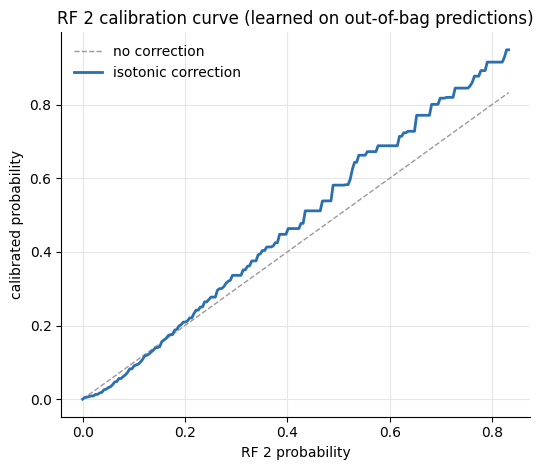

In [28]:
# Step 6.1 Isotonic calibration of RF 2, learned on its out-of-bag (honest) training predictions
p_oob = rf2.oob_decision_function_[:, 1]                             # each training row's lapse probability from the trees that didn't see it
ok = np.isfinite(p_oob)                                              # (a row seen by every tree would have no OOB prediction; normally none)
calibrator = IsotonicRegression(out_of_bounds="clip",                # scores outside the training range get the nearest end of the curve
                                y_min=1e-4, y_max=1 - 1e-4)          # never exactly 0% or 100% (log loss would be infinite)
calibrator.fit(p_oob[ok], y_train.to_numpy()[ok])                    # learn: forest score -> real lapse rate
print(f"calibration learned on {ok.sum():,} out-of-bag predictions ({(~ok).sum()} rows without one)")

def calibrated(p):
    '''Apply the calibration curve to RF 2 probabilities.'''
    return calibrator.predict(p)                                     # look up each score on the curve

# The curve as a picture: forest score (x) -> calibrated probability (y)
grid = np.linspace(0, np.quantile(p_oob[ok], 0.999), 200)            # forest scores from 0 to almost the highest
fig, ax = plt.subplots(figsize=(5.5, 4.8))
ax.plot([0, grid.max()], [0, grid.max()], color="#9a9a9a", linestyle="--", linewidth=1, label="no correction")
ax.plot(grid, calibrated(grid), color="#2a6fb0", linewidth=2, label="isotonic correction")
ax.set(title="RF 2 calibration curve (learned on out-of-bag predictions)",
       xlabel="RF 2 probability", ylabel="calibrated probability")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e6e6e6")
plt.tight_layout(); plt.show()

### Section 7. Out-of-time test results (OOT1, 2021–2022)
#### 7.1 Score every test row
Every test row (7.1M) is scored in 28 pieces by RF 1, RF 2 and RF 2 + calibration, next to the two benchmarks. The validation years (2023–2024) stay untouched until notebook 08. Expect this to take several minutes.

In [29]:
# Step 7.1 Score every test row (2021-2022), piece by piece
t0 = time.time()                                                     # start the stopwatch
parts = []                                                           # the scored pieces collect here
for k in range(N_CHUNKS):                                            # for each of the 28 pieces ...
    X, y, ids = load_rows("test", where=chunk_filter(k))             # load that piece
    Z = preprocess.transform(X).astype(np.float32)                   # prepare it (with what was learned on train)
    p2 = rf2.predict_proba(Z)[:, 1]                                  # RF 2 probabilities
    parts.append(pd.DataFrame({
        "period_id": ids["period_id"].to_numpy(),                    # row id
        "period_year": ids["period_year"].to_numpy(),                # 2021 or 2022
        "y": y.to_numpy(),                                           # what actually happened (1 = lapsed)
        "p_rf1": rf1.predict_proba(Z)[:, 1],                         # RF 1 probability
        "p_rf2": p2,                                                 # RF 2 probability
        "p_rf2_cal": calibrated(p2),                                 # RF 2 + calibration probability
        "new_business": X["new_business"].fillna(0).astype(int).to_numpy(),           # for the segment benchmark
        "mandatory_purchase": X["mandatory_purchase"].fillna(0).astype(int).to_numpy(),
        "acs_missing": X["acs_median_income"].isna().to_numpy(),    # was the ACS data missing? (for the check in 7.4)
    }))
pred = pd.concat(parts, ignore_index=True)                           # stack the pieces into one table
del parts, X, y, ids, Z                                              # free the memory

pred["p_base"] = base_rate                                           # benchmark 1: everyone gets the training lapse rate
pred = pred.merge(segment_rates[["new_business", "mandatory_purchase", "segment_rate"]],   # benchmark 2: the segment's training rate
                  on=["new_business", "mandatory_purchase"], how="left")
pred["p_segment"] = pred.pop("segment_rate").fillna(base_rate)       # a segment not seen in training gets the base rate
print(f"scored {len(pred):,} test rows in {(time.time() - t0) / 60:.1f} min; lapse rate {pred['y'].mean():.3%}")

scored 7,105,637 test rows in 2.7 min; lapse rate 12.020%


#### 7.2 Results against the benchmarks and the logistic regression
Same scores as 06b:
- **Log loss** (main score) and **Brier score**: lower is better.
- **Skill**: improvement over the base rate in the same period. 0% = no better than giving everyone the average; higher is better.

The logistic regression's results are read from `reports/lapse_baseline_logreg_test_metrics.csv` (saved by 06b), so it is not retrained here. It was scored on the same 7.1M test rows.

In [30]:
# Step 7.2 Results: the forests against the benchmarks (and the logistic regression from 06b)
MODELS = {"base rate": "p_base", "segment rate": "p_segment",       # model name -> its column in pred
          "RF 1 (starting settings)": "p_rf1", "RF 2 (tuned)": "p_rf2", "RF 2 + calibration": "p_rf2_cal"}

def scores(y, p):
    '''The scores for one set of rows: counts, rates, log loss and Brier.'''
    return {"rows": len(y), "lapses": int(y.sum()), "actual_rate": y.mean(), "predicted_rate": p.mean(),
            "log_loss": log_loss(y, p, labels=[0, 1]), "brier": brier_score_loss(y, p)}

rows = []                                                            # one row per period x model
for scope, part in [("2021-2022", pred), *[(str(y), g) for y, g in pred.groupby("period_year")]]:   # both years together, then each year
    for name, col in MODELS.items():                                 # every model
        rows.append({"scope": scope, "model": name, **scores(part["y"], part[col])})
results = pd.DataFrame(rows)

logreg_file = REPORTS / "lapse_baseline_logreg_test_metrics.csv"     # 06b's saved results
if logreg_file.exists():                                             # if a teammate has shared it ...
    lr = pd.read_csv(logreg_file)
    lr = lr[lr["model"] == "logistic regression"]                    # ... add the logistic regression rows
    results = pd.concat([results, lr[[c for c in results.columns if c in lr.columns]]], ignore_index=True)
    results["scope"] = results["scope"].astype(str)
else:
    print(f"(not found: {logreg_file.name}; ask Sebastian to push it, then re-run this cell)")

base = results[results["model"] == "base rate"].set_index("scope")  # the base rate's scores, per period
results["log_loss_skill"] = 1 - results["log_loss"] / results["scope"].map(base["log_loss"])   # improvement in log loss over the base rate
results["brier_skill"] = 1 - results["brier"] / results["scope"].map(base["brier"])            # improvement in Brier over the base rate
results = results.sort_values(["scope", "log_loss"]).reset_index(drop=True)   # best model first within each period
results.style.format({"rows": "{:,}", "lapses": "{:,}", "actual_rate": "{:.3%}", "predicted_rate": "{:.3%}",
                      "log_loss": "{:.5f}", "brier": "{:.6f}", "log_loss_skill": "{:+.2%}", "brier_skill": "{:+.2%}"})

,scope,model,rows,lapses,actual_rate,predicted_rate,log_loss,brier,log_loss_skill,brier_skill
0,2021,RF 2 (tuned),"3,648,441","465,877",12.769%,11.708%,0.35204,0.104364,+7.96%,+6.40%
1,2021,RF 2 + calibration,"3,648,441","465,877",12.769%,11.020%,0.35294,0.104435,+7.72%,+6.34%
2,2021,RF 1 (starting settings),"3,648,441","465,877",12.769%,11.451%,0.35571,0.105292,+7.00%,+5.57%
3,2021,logistic regression,"3,648,441","465,877",12.769%,11.664%,0.36508,0.107338,+4.55%,+3.73%
4,2021,segment rate,"3,648,441","465,877",12.769%,13.102%,0.37728,0.110135,+1.36%,+1.23%
5,2021,base rate,"3,648,441","465,877",12.769%,13.839%,0.38247,0.111501,+0.00%,+0.00%
6,2021-2022,RF 2 (tuned),"7,105,637","854,084",12.020%,12.205%,0.34460,0.100613,+6.55%,+5.15%
7,2021-2022,RF 2 + calibration,"7,105,637","854,084",12.020%,11.593%,0.34554,0.100810,+6.30%,+4.97%
8,2021-2022,RF 1 (starting settings),"7,105,637","854,084",12.020%,11.628%,0.34620,0.101011,+6.12%,+4.78%
9,2021-2022,logistic regression,"7,105,637","854,084",12.020%,11.857%,0.35129,0.102191,+4.74%,+3.67%


#### 7.3 Calibration and lapses captured, by decile
The test policy-years are sorted by RF 2 + calibration's probability and cut into 10 equal groups (decile 10 = highest probability).
- **Calibration:** in each decile, the mean predicted probability should match the actual lapse rate (points on the diagonal).
- **Share of lapses:** what share of all lapses falls in each decile. This is the number behind "the riskiest 10% of policies hold X% of the lapses" for the presentation.

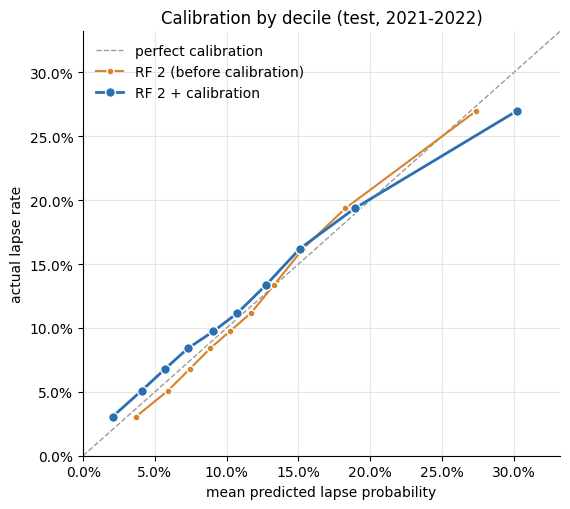

,actual,expected_base rate,expected_segment rate,expected_RF 1 (starting settings),expected_RF 2 (tuned),expected_RF 2 + calibration
period_year,,,,,,
2021,"465,877","504,917","478,033","417,769","427,156","402,057"
2022,"388,207","478,451","473,704","408,451","440,105","421,719"
2021-2022,"854,084","983,368","951,737","826,220","867,261","823,776"


,rows,lapses,predicted,actual,rf2_uncalibrated,actual_to_predicted,share_of_lapses,cumulative_share
decile,,,,,,,,
10,"710,564","191,712",30.200%,26.980%,27.372%,0.89,22.4%,22.4%
9,"710,564","137,552",18.915%,19.358%,18.263%,1.02,16.1%,38.6%
8,"710,563","115,177",15.099%,16.209%,15.325%,1.07,13.5%,52.0%
7,"710,564","94,949",12.739%,13.362%,13.295%,1.05,11.1%,63.2%
6,"710,563","79,321",10.744%,11.163%,11.681%,1.04,9.3%,72.4%
5,"710,564","69,240",9.081%,9.744%,10.226%,1.07,8.1%,80.5%
4,"710,564","59,757",7.301%,8.410%,8.855%,1.15,7.0%,87.5%
3,"710,563","48,456",5.732%,6.819%,7.454%,1.19,5.7%,93.2%
2,"710,564","36,129",4.066%,5.085%,5.899%,1.25,4.2%,97.4%


In [35]:
# Step 7.3 Calibration by decile (RF 2 + calibration), with the share of lapses in each decile
from matplotlib.ticker import PercentFormatter                       # shows axis numbers as percentages

MAIN = "p_rf2_cal"                                                   # the model carried forward
pred["decile"] = pd.qcut(pred[MAIN].rank(method="first"), 10, labels=range(1, 11)).astype(int)   # 10 equal groups; 10 = highest probability
deciles = (pred.groupby("decile")
               .agg(rows=("y", "size"), lapses=("y", "sum"), predicted=(MAIN, "mean"), actual=("y", "mean"),
                    rf2_uncalibrated=("p_rf2", "mean"))              # RF 2 before calibration, for comparison
               .sort_index(ascending=False))                         # highest-risk decile first
deciles["actual_to_predicted"] = deciles["actual"] / deciles["predicted"]   # 1 = perfectly calibrated
deciles["share_of_lapses"] = deciles["lapses"] / deciles["lapses"].sum()    # share of all test lapses in this decile
deciles["cumulative_share"] = deciles["share_of_lapses"].cumsum()           # top 1, top 2, ... deciles together

fig, ax = plt.subplots(figsize=(5.8, 5.2))
lim = max(deciles[["predicted", "actual", "rf2_uncalibrated"]].max()) * 1.1   # axis limit
ax.plot([0, lim], [0, lim], color="#9a9a9a", linewidth=1, linestyle="--", label="perfect calibration")
ax.plot(deciles["rf2_uncalibrated"], deciles["actual"], color="#d9822b", linewidth=1.5, marker="o", markersize=5,
        markeredgecolor="white", label="RF 2 (before calibration)")
ax.plot(deciles["predicted"], deciles["actual"], color="#2a6fb0", linewidth=2, marker="o", markersize=7,
        markeredgecolor="white", label="RF 2 + calibration")
ax.set(title="Calibration by decile (test, 2021-2022)", xlabel="mean predicted lapse probability",
       ylabel="actual lapse rate", xlim=(0, lim), ylim=(0, lim))
ax.xaxis.set_major_formatter(PercentFormatter(1, decimals=1)); ax.yaxis.set_major_formatter(PercentFormatter(1, decimals=1))
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / "fig_lapse_rf_calibration.png", dpi=150)      # saved for the slides and poster
plt.show()

# Expected lapses (sum of the probabilities) vs actual lapses, per test year and model
expected = (pred.groupby("period_year")
                .agg(actual=("y", "sum"), **{f"expected_{n}": (c, "sum") for n, c in MODELS.items()}))
expected.loc["2021-2022"] = expected.sum()                          # both years together
display(expected.style.format("{:,.0f}"))
deciles.style.format({"rows": "{:,}", "lapses": "{:,}", "predicted": "{:.3%}", "actual": "{:.3%}",
                      "rf2_uncalibrated": "{:.3%}", "actual_to_predicted": "{:.2f}",
                      "share_of_lapses": "{:.1%}", "cumulative_share": "{:.1%}"})

#### 7.4 Check: is the missing-ACS leak closed?
Rows whose ACS data was missing lapse far more often (notebook 05, 5.2d), but the team decided the model must not use that. If the random filling works, the forest **can't tell** these rows apart, so:
- its mean prediction for ACS-missing rows should be close to its prediction for the other rows (in the first run, with the median fill: about 23% against 8%);
- ACS-missing rows should make up about the same share of every decile as of all rows (first run: 48% of the top decile, against 11% overall).

The actual lapse rates will still differ a lot between the two groups: that is the information we chose not to use.

In [36]:
# Step 7.4 Check that the forest can no longer pick out the rows with missing ACS data
check = (pred.groupby("acs_missing")
             .agg(rows=("y", "size"), actual=("y", "mean"), predicted=(MAIN, "mean"))
             .rename(index={False: "ACS present", True: "ACS missing"}))      # lapse rate vs mean prediction, per group
check["share_of_rows"] = check["rows"] / check["rows"].sum()                   # each group's share of the test rows
display(check.style.format({"rows": "{:,}", "actual": "{:.2%}", "predicted": "{:.2%}", "share_of_rows": "{:.1%}"}))

by_decile = pred.groupby("decile")["acs_missing"].mean().sort_index(ascending=False)   # share of ACS-missing rows in each decile
print(f"share of ACS-missing rows: {pred['acs_missing'].mean():.1%} of all test rows; "
      f"{by_decile.loc[10]:.1%} of the top decile (first run with the median fill: 48%)")
by_decile.to_frame("share_acs_missing").T.style.format("{:.1%}")

,rows,actual,predicted,share_of_rows
acs_missing,,,,
ACS present,"6,298,751",8.46%,11.22%,88.6%
ACS missing,"806,886",39.79%,14.50%,11.4%


share of ACS-missing rows: 11.4% of all test rows; 18.6% of the top decile (first run with the median fill: 48%)


decile,10,9,8,7,6,5,4,3,2,1
share_acs_missing,18.6%,17.0%,14.9%,12.7%,11.0%,10.0%,9.1%,7.9%,6.8%,5.6%


#### 7.5 Premium at risk by decile (DRAFT)
This turns the lapse probabilities into money, so managers can see **how much premium is at risk** and what a retention campaign could be worth.

**Expected premium lost** for a policy-year = lapse probability × annual premium. A $1,000 policy with a 27% lapse probability carries $270 of expected lost premium. Summed by decile, this shows where the money at risk is concentrated. We also add up the **actual** premium of the policy-years that really lapsed, to check the forecast.

**Why this is a draft:**
- It uses **RF 2 (uncalibrated)** on the **2021–2022** test years. The final figures for the slides should come from the model the team chooses, scored once on the **2023–2024** holdout in notebook 08. The calculation stays the same; only the probabilities change.
- The campaign numbers use **assumptions** (save rate, cost per contact), set at the top of the cell. Replace them with real figures, or present them as "if … then …".

It uses the test predictions from Section 7; in a fresh session it reads the ones saved in Step 9.1 instead, so it can run on its own after Sections 0.1 and 1.1 (no need to retrain).

Figures are in **US$ per year** (2021–2022 totals divided by 2).

In [ ]:
# Step 7.5 Premium at risk by decile (DRAFT: RF 2 on test 2021-2022; final figures come from the chosen model in notebook 08)
SAVE_RATE = 0.10            # ASSUMPTION: share of contacted would-be lapsers that a retention call keeps (replace when measured)
COST_PER_CONTACT = 20.0     # ASSUMPTION: cost in US$ of one retention contact (replace with a real figure)
TOP_DECILES = 3             # campaign: contact the 3 riskiest deciles (the riskiest 30% of policy-years)
N_YEARS = 2                 # 2021 and 2022: totals are divided by 2 to show "per year"
PRED_FILE = PROCESSED / "predictions" / "lapse_rf_test.parquet"   # the RF test predictions saved in Step 9.1

# The RF 2 test predictions: from memory if Section 7 just ran, otherwise from the file saved in Step 9.1
if "pred" in globals():
    con.register("rf_pred", pred[["period_id", "y", "p_rf2"]])     # let DuckDB read the table in memory
else:
    con.execute(f"CREATE OR REPLACE VIEW rf_pred AS SELECT period_id, y, p_rf2 FROM read_parquet('{PRED_FILE}')")

# Each test policy-year's RF 2 probability, what happened, and its annual premium
money = con.sql('''
    SELECT p.period_id, p.y, p.p_rf2,
           CASE WHEN f.premium > 0 THEN f.premium END AS premium     -- negative premiums are refunds or errors (as in apply_fixed_rules)
    FROM rf_pred p
    JOIN lapse_pop f USING (period_id)
''').df()                                                           # one row per test policy-year
print(f"{len(money):,} test policy-years; premium missing or negative for {money['premium'].isna().mean():.2%} (counted as $0)")
money["premium"] = money["premium"].fillna(0)                       # no usable premium -> no money at risk

money["expected_loss"] = money["p_rf2"] * money["premium"]          # expected lost premium = probability x premium
money["actual_loss"] = money["y"] * money["premium"]                # premium of the policy-years that really lapsed
money["decile"] = pd.qcut(money["p_rf2"].rank(method="first"), 10, labels=range(1, 11)).astype(int)   # 10 = riskiest

par = (money.groupby("decile")
            .agg(policy_years=("y", "size"), premium=("premium", "sum"), predicted_rate=("p_rf2", "mean"),
                 actual_rate=("y", "mean"), expected_loss=("expected_loss", "sum"), actual_loss=("actual_loss", "sum"))
            .sort_index(ascending=False))                           # riskiest decile first
for col in ["policy_years", "premium", "expected_loss", "actual_loss"]:
    par[col] = par[col] / N_YEARS                                   # per year
par["avg_premium"] = par["premium"] / par["policy_years"]           # average premium in the decile
par["share_of_actual_loss"] = par["actual_loss"] / par["actual_loss"].sum()   # share of all premium lost
par["cumulative_share"] = par["share_of_actual_loss"].cumsum()      # top 1, top 2, ... deciles together
par.loc["Total"] = par.sum()                                        # a total row ...
par.loc["Total", ["predicted_rate", "actual_rate"]] = [money["p_rf2"].mean(), money["y"].mean()]   # ... with overall rates
par.loc["Total", "avg_premium"] = par.loc["Total", "premium"] / par.loc["Total", "policy_years"]
par.loc["Total", "cumulative_share"] = np.nan                       # not meaningful for the total

# Chart: expected vs actual premium lost per year, by decile
show = par.drop(index="Total")
fig, ax = plt.subplots(figsize=(8, 4.5))
x = np.arange(len(show))                                            # one position per decile
ax.bar(x - 0.2, show["expected_loss"] / 1e6, width=0.4, color="#2a6fb0", label="expected (RF 2)")
ax.bar(x + 0.2, show["actual_loss"] / 1e6, width=0.4, color="#d9822b", label="actual")
ax.set_xticks(x, [str(d) for d in show.index])
ax.set(title="Premium lost to lapse per year, by risk decile (test 2021-2022, DRAFT)",
       xlabel="risk decile (10 = riskiest)", ylabel="US$ millions per year")
ax.legend(frameon=False); ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="y", color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / "fig_lapse_rf_premium_at_risk_draft.png", dpi=150)   # saved for the slides and poster
plt.show()

# Illustrative campaign: contact the riskiest TOP_DECILES deciles
top = show.head(TOP_DECILES)                                        # the riskiest deciles
contacts = top["policy_years"].sum()                                # policies contacted per year
kept = top["expected_loss"].sum() * SAVE_RATE                       # premium kept per year = premium at risk x save rate
cost = contacts * COST_PER_CONTACT                                  # campaign cost per year
print(f"Campaign (illustrative): contact the riskiest {TOP_DECILES * 10}% = {contacts:,.0f} policies a year; "
      f"they hold ${top['expected_loss'].sum() / 1e6:,.0f}M of expected lost premium "
      f"({top['actual_loss'].sum() / show['actual_loss'].sum():.0%} of all premium actually lost).\n"
      f"If {SAVE_RATE:.0%} of would-be lapsers are kept: ${kept / 1e6:,.1f}M premium kept, "
      f"cost ${cost / 1e6:,.1f}M at ${COST_PER_CONTACT:,.0f} a contact, net ${(kept - cost) / 1e6:,.1f}M a year.")

par.to_csv(REPORTS / "lapse_rf_premium_at_risk_draft.csv")          # saved for notebook 08 and the slides
par.style.format({"policy_years": "{:,.0f}", "premium": "${:,.0f}", "avg_premium": "${:,.0f}",
                  "predicted_rate": "{:.2%}", "actual_rate": "{:.2%}", "expected_loss": "${:,.0f}",
                  "actual_loss": "${:,.0f}", "share_of_actual_loss": "{:.1%}", "cumulative_share": "{:.1%}"}, na_rep="")

### Section 8. What drives the forest
A forest has no coefficients to read, so we measure each feature's importance by **permutation**: shuffle one feature's values across the rows (breaking its link with lapse) and see how much the log loss gets worse. A big increase = the model relies on that feature.

This is done on 50,000 test rows, 3 shuffles per feature, on RF 2 (calibration only rescales its probabilities). It answers *which* features matter, not in which direction; notebook 09 (SHAP) shows the direction for individual policies.

done in 1.6 min


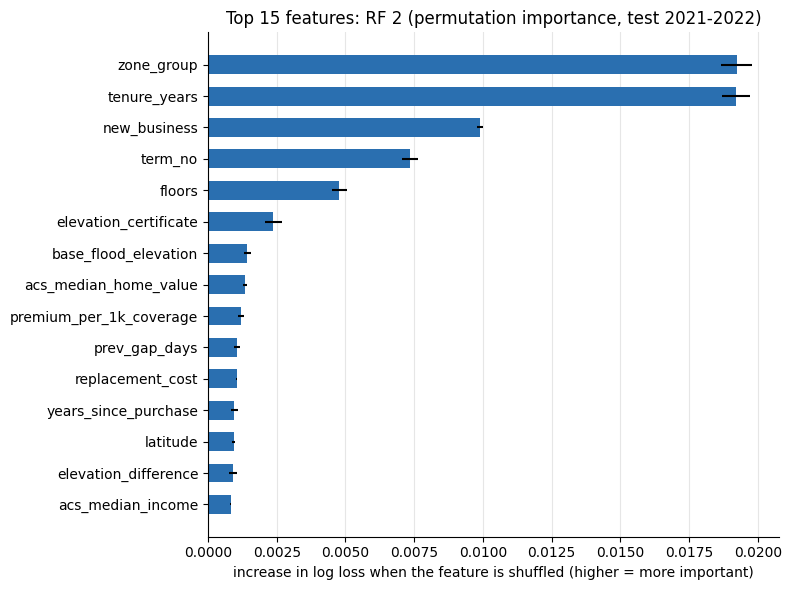

,feature,log_loss_increase,std,group,kind
0,zone_group,0.01923,0.00055,flood_risk,cat
1,tenure_years,0.01921,0.00050,tenure,num
2,new_business,0.00989,0.00011,tenure,flag
3,term_no,0.00734,0.00029,tenure,num
4,floors,0.00478,0.00029,property,cat
5,elevation_certificate,0.00238,0.00030,flood_risk,cat
6,base_flood_elevation,0.00144,0.00012,flood_risk,num
7,acs_median_home_value,0.00135,0.00008,context,num
8,premium_per_1k_coverage,0.00121,0.00010,price,num
9,prev_gap_days,0.00107,0.00011,history,num


In [37]:
# Step 8.1 Permutation importance on 50,000 test rows (how much worse the log loss gets when a feature is shuffled)
from sklearn.inspection import permutation_importance              # the shuffling method

model_rf2 = make_pipeline(preprocess, rf2)                           # preparation + RF 2 as one object (both already fitted)
X_imp, y_imp, _ = load_rows("test", sample_rows=50_000, seed=SEED + 2)   # a fresh random test sample
t0 = time.time()                                                     # start the stopwatch
imp = permutation_importance(model_rf2, X_imp, y_imp, scoring="neg_log_loss",   # shuffle each ORIGINAL feature, score by log loss
                             n_repeats=3, random_state=SEED, n_jobs=1)          # 3 shuffles each, averaged
importance = (pd.DataFrame({"feature": FEATS,
                            "log_loss_increase": imp.importances_mean,          # average worsening of the log loss
                            "std": imp.importances_std})                        # how much it varies between shuffles
                .merge(plan[["feature", "group", "kind"]], on="feature")       # add the feature group (price, tenure, ...)
                .sort_values("log_loss_increase", ascending=False).reset_index(drop=True))
print(f"done in {(time.time() - t0) / 60:.1f} min")

top = importance.head(15)                                            # the 15 most important features
fig, ax = plt.subplots(figsize=(8, 6))
ax.barh(top["feature"][::-1], top["log_loss_increase"][::-1], xerr=top["std"][::-1], color="#2a6fb0", height=0.6)
ax.set(title="Top 15 features: RF 2 (permutation importance, test 2021-2022)",
       xlabel="increase in log loss when the feature is shuffled (higher = more important)")
ax.spines[["top", "right"]].set_visible(False); ax.grid(axis="x", color="#e6e6e6"); ax.set_axisbelow(True)
plt.tight_layout()
plt.savefig(REPORTS / "fig_lapse_rf_importance.png", dpi=150)       # saved for the slides and poster
plt.show()
importance.head(20).style.format({"log_loss_increase": "{:.5f}", "std": "{:.5f}"})

### Section 9. Save
#### 9.1 Save the model and results
Same places and naming as 06b: the model in `data/processed/models/`, the test predictions in `data/processed/predictions/` (both stay off GitHub), and the tables, figures and run record in `reports/` (pushed to GitHub).

To use the saved model elsewhere: `p = calibrator.predict(model.predict_proba(preprocess.transform(X))[:, 1])`.

In [34]:
# Step 9.1 Save the model, the test predictions and the results
import json                                                          # writes the run record
import joblib                                                        # saves Python objects (the model) to a file
from datetime import datetime                                        # the time stamp

MODEL_DIR = PROCESSED / "models"                                     # models folder (not on GitHub)
PRED_DIR = PROCESSED / "predictions"                                 # predictions folder (not on GitHub)
for d in (MODEL_DIR, PRED_DIR):
    d.mkdir(parents=True, exist_ok=True)                             # create them if needed
NAME = "lapse_rf"                                                    # file name prefix for this model

# The model: preparation + RF 2 + calibration curve, in one file
joblib.dump({"preprocess": preprocess, "model": rf2, "calibrator": calibrator, "features": FEATS},
            MODEL_DIR / f"{NAME}.joblib", compress=3)                # compress: forests are large files

# Test predictions, row by row, so notebook 08 can compare models without retraining
pred[["period_id", "period_year", "y", "p_rf1", "p_rf2", "p_rf2_cal", "p_segment", "p_base"]].to_parquet(
    PRED_DIR / f"{NAME}_test.parquet", index=False)

# Results tables for GitHub
results.to_csv(REPORTS / f"{NAME}_test_metrics.csv", index=False)
deciles.to_csv(REPORTS / f"{NAME}_test_deciles.csv")
tuning.to_csv(REPORTS / f"{NAME}_tuning.csv", index=False)
importance.to_csv(REPORTS / f"{NAME}_permutation_importance.csv", index=False)

# Run record: what was trained, on what, with which settings
run = {
    "model": NAME, "target": TARGET, "saved_at": datetime.now().isoformat(timespec="seconds"),
    "train_split": f"train (2014-2020), random sample of {TRAIN_ROWS:,} rows (seed {SEED})",
    "tuning": f"rolling-origin folds 2017-2020 on {TUNE_ROWS:,} rows; best min_samples_leaf={BEST_LEAF}, max_features={BEST_MAXF}",
    "calibration": "isotonic, fitted on RF 2 out-of-bag predictions",
    "random_filled_features": num_random,                            # filled with random training values (run 2)
    "scored_on": "test (2021-2022), every row",
    "features_used": FEATS, "model_columns": int(len(COLS)),
    "params": {k: (v if isinstance(v, (int, float, str, bool, type(None))) else str(v)) for k, v in rf2.get_params().items()},
    "seed": SEED, "base_rate_train": base_rate,
    "test_overall": results.query("scope == '2021-2022' and model == 'RF 2 + calibration'").iloc[0].drop(["scope", "model"]).to_dict(),
}
(REPORTS / f"{NAME}_run.json").write_text(json.dumps(run, indent=2, default=float))

# Check: the saved model loads and gives the same predictions
saved = joblib.load(MODEL_DIR / f"{NAME}.joblib")                    # read it back
X_check, _, _ = load_rows("test", sample_rows=1000)                  # 1,000 test rows
p_saved = saved["calibrator"].predict(saved["model"].predict_proba(saved["preprocess"].transform(X_check).astype(np.float32))[:, 1])
p_now = calibrated(rf2.predict_proba(preprocess.transform(X_check).astype(np.float32))[:, 1])
print(f"saved {NAME}.joblib ({(MODEL_DIR / f'{NAME}.joblib').stat().st_size / 1e6:.0f} MB), test predictions, "
      f"metrics, deciles, tuning, importance and run record; reload gives the same predictions: {np.allclose(p_saved, p_now)}")

saved lapse_rf.joblib (111 MB), test predictions, metrics, deciles, tuning, importance and run record; reload gives the same predictions: True


### Findings

- **Best model:**: RF 2 (tuned, without calibration). On test 2021–22: log loss 0.3446, **6.6% better than the base rate**, vs. 4.7% for logistic regression and 2.9% for the segment rule. The advantage comes from 2021 (+8.0% vs. +4.6%); in 2022 RF and logistic perform alike (+5.0%).
- **Tuning:** min_samples_leaf=25, max_features="sqrt". Year-to-year differences were about 10× larger than differences between settings.
- **Calibration:** isotonic calibration made results slightly worse (0.3455), so RF 2 is used uncalibrated. RF 2 expects 867K lapses vs. 854K actual (+1.5%), though by year it misses −8% (2021) and +13% (2022).
- **Riskiest:** the riskiest 10% lapse at 27% (9× the safest 10%) and hold 22% of lapses; the riskiest 30% hold 52%.
- **Leak fixed (run 2):** with a median fill, the forest singled out rows with missing ACS data (48% of the top decile). Random-draw filling cut that to 18.6% (11.4% overall), and the skill fell from 11.6% to 6.6%, the honest result.
- **Main drivers:** lood zone and tenure (tied), then new business, term number, floors and elevation certificate. Price per $1,000 of cover is moderate. Mandatory purchase, premium increases and recent disasters rank low.
